# 04 · Three versions of 30 m segments from the same photons: current, check, and new

**Question:** for the same ATL03 v007 photons in the G-LiHT tiles, how do the 30 m heights built from the **reclassified photon
classes** differ from the **current v7 30 m segments** in our training files, and how much of that difference comes from the
photon classification rather than from how the photons are binned into 30 m segments?

- **current v7 30 m (ATL08 classes → PhoREAL):** SlideRule PhoREAL on the ATL08 v007 photon classes, with the settings of
  `process_atl08_boreal.py` (1 m vertical bins, `geoloc=center`, ABoVE top-of-canopy classifier).
- **ATL08 classes → our 30 m (check):** our binning (`segment_metrics`) of the same ATL08 v007 photon classes, heights above a
  ground drawn through the ATL08 ground photons.
- **reclassified photons → our 30 m (new):** our binning of the reclassified photon classes (v0.1), with the short-vegetation guard.

Current vs check isolates the binning; check vs new isolates the classification; current vs new is what would change in training.

### Terms used in this notebook (same in every notebook of this series)

**Photons and their classes**
| Term | What it is |
|---|---|
| **ATL03 v007 photons** | Every photon ICESat-2 recorded (signal and solar background), with height and position. Nothing is classified yet. |
| **ATL08 v007 photon classes** | NASA's labels for those photons (noise / ground / canopy / top of canopy), from the ATL08 product. Our current training data are built from these. |
| **Reclassified photon classes (v0.1)** | Our own labels for the **same** photons, from `lib/icesat2_photon_lib.py: reclassify` with the thresholds in `config/atl03_reclass_v0.1.yaml`. |
| **Reference photon labels** | Labels from airborne lidar (G-LiHT) or UAV surface models: a photon at the reference ground is ground, between ground and the reference canopy top is canopy, far above or below is noise. Treated as the truth. |

**30 m segments (ATL08-style along-track segments), three versions from the same photons**
| Term | Photon classes used | 30 m binning | Role |
|---|---|---|---|
| **current v7 30 m (ATL08 classes → PhoREAL)** | ATL08 v007 | SlideRule PhoREAL (as in `process_atl08_boreal.py`) | What our training files contain today |
| **ATL08 classes → our 30 m (check)** | ATL08 v007 | ours (`segment_metrics`) | Check: separates the effect of our binning from our classification |
| **reclassified photons → our 30 m (new)** | reclassified v0.1 | ours (`segment_metrics`) | The new product being tested |

`h_canopy` = 98th percentile of canopy-photon heights above the ground in a 30 m segment (as in ATL08).
**Reference height** of a segment = 98th percentile of the 1 m reference canopy height model (G-LiHT or UAV) inside the segment's footprint (30 m along track × 11 m).

In [1]:
import sys, os, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

REPO = Path.cwd().resolve().parents[1]          # notebooks/atl03_reclass -> repo root
sys.path.insert(0, str(REPO / "lib"))
import icesat2_photon_lib as ipl, reference_lib as ref, validation_lib as val

cfg = ipl.load_config(REPO / "config" / "atl03_reclass_v0.1.yaml")   # profile auto: 'maap' on MAAP ADE, else 'adapt'
WORK = Path(cfg["paths"]["work_dir"]); WORK.mkdir(parents=True, exist_ok=True)
FIG = WORK / "figures"; FIG.mkdir(exist_ok=True)
print("profile:", cfg["profile"], "| config", cfg["version"], cfg["config_sha1"], "| work_dir:", WORK)
print(json.dumps(ipl.provenance(cfg), indent=1))

profile: adapt | config 0.1 d49984a76293 | work_dir: /explore/nobackup/people/pmontesa/atl03_reclass


{
 "repo": "circumpolar_boreal_trends",
 "git_commit": "7d697cc",
 "git_dirty_lib_or_config": true,
 "config_version": "0.1",
 "config_sha1": "d49984a76293",
 "sliderule_client": "5.6.3",
 "processed_utc": "2026-10-15T08:47:23"
}


## Build the three versions of 30 m segments for each G-LiHT tile

**Input:** the photons with both classifications (notebook 03) and the PhoREAL segments downloaded in notebook 02.

**What happens:**
- **reclassified photons → our 30 m (new):** `segment_metrics` on `class_new` / `relief_new`, including the short-vegetation guard.
- **ATL08 classes → our 30 m (check):** `segment_metrics` on `atl08_class` / `relief_atl08`.
- **current v7 30 m (ATL08 classes → PhoREAL):** read from `phoreal.parquet`.
- The three are matched by track and position (nearest within 20 m). Each segment also gets the share of its photons in
  disturbed forest (notebook 02, step 6).

**Output:** `segments/tile_<n>_segments.parquet`: one row per new segment, with `h_canopy` (new), `h_canopy_atl08` (check) and
`h_canopy_phoreal` (current).

In [2]:
GL = WORK / "glihit"; OUT = WORK / "segments"; OUT.mkdir(exist_ok=True)
ph = gpd.read_parquet(WORK / "reclass" / "glihit_photons_reclassified.parquet")
tiles = sorted(ph.tile_num.unique())
segs = []
for t in tiles:
    fn = OUT / f"tile_{t}_segments.parquet"
    if fn.exists():
        segs.append(gpd.read_parquet(fn)); continue
    p = ph[ph.tile_num == t]
    s_new = ipl.segment_metrics(p, cfg, "class_new", "relief_new", "new")
    s_nat = ipl.segment_metrics(p, cfg, "atl08_class", "relief_atl08", "atl08")
    keep = ["h_canopy", "n_canopy", "n_ground", "Ev", "Eg"]
    s = ipl.match_segments(s_new, s_nat[["track_id", "geometry"] + keep], keep, suffix="_atl08")
    prf = GL / f"tile_{t}" / "phoreal.parquet"
    if prf.exists():
        pr = gpd.read_parquet(prf).to_crs(4326)
        s = ipl.match_segments(s, pr[["track_id", "geometry", "h_canopy", "canopy_openness"]], ["h_canopy", "canopy_openness"], suffix="_phoreal")
    # share of disturbed photons per segment (from notebook 02)
    p = p.assign(seg=np.floor(p.x_atc / cfg["segments"]["length_m"]).astype(int))
    d = p.groupby(["track_id", "seg"]).agg(disturbed_frac=("disturbed", "mean"), region=("region", "first"), als_year=("als_year", "first")).reset_index()
    s = s.merge(d, on=["track_id", "seg"], how="left")
    s["tile_num"] = t
    ipl.write_parquet(s, fn, ipl.provenance(cfg, tile_num=int(t)))
    segs.append(s)
segs = gpd.GeoDataFrame(pd.concat(segs, ignore_index=True), crs=4326)
print(len(segs), "segments;", segs.groupby("region").size().to_dict())

35427 segments; {'Interior': 22482, 'Kenai': 12945}


## Check: does our 30 m binning reproduce PhoREAL?

Both axes use the **ATL08 v007 photon classes**; only the binning differs: **ATL08 classes → our 30 m (check)** (y) vs
**current v7 30 m (ATL08 classes → PhoREAL)** (x). If they agree, any difference between "current" and "new" below comes
from the photon classification. If they don't, part of it comes from the binning and has to be accounted for (in notebook 01
our binning gave higher heights than PhoREAL from the same classes).

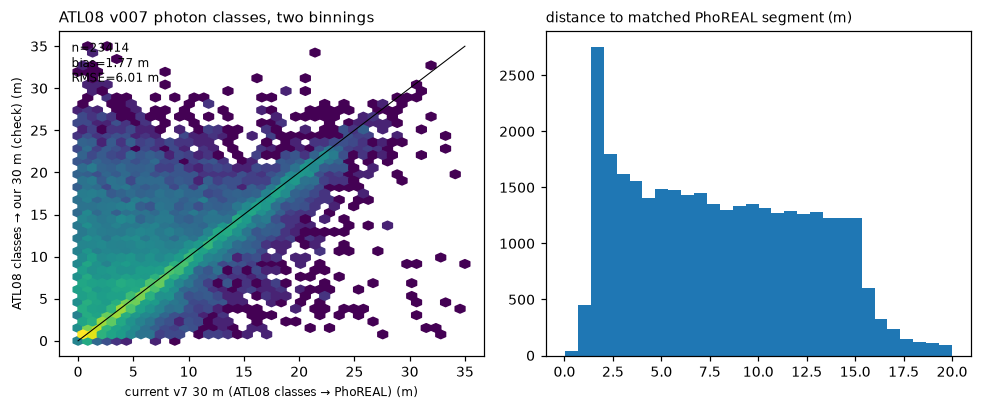

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
val.plot_scatter(axes[0], segs.h_canopy_atl08, segs.h_canopy_phoreal, "ATL08 v007 photon classes, two binnings", lim=35)
axes[0].set_xlabel(val.LABEL_CURRENT + " (m)", fontsize=8); axes[0].set_ylabel(val.LABEL_CHECK + " (m)", fontsize=8)
axes[1].hist(segs.match_dist_m.dropna(), bins=30); axes[1].set_title("distance to matched PhoREAL segment (m)", loc="left", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "04_binning_check.png", dpi=150)

## New vs current: how the reclassified 30 m heights differ from what our training files contain

Left: **reclassified photons → our 30 m (new)** vs **current v7 30 m (ATL08 classes → PhoREAL)** for the same segments.
Middle: the difference (new − current) by current height. Right: height distributions per region. This is a comparison of
the two products, not a validation; notebook 05 compares both with G-LiHT.

,segments,short_veg_flag,matched_to_phoreal
region,,,
Interior,22482,0.662,0.939
Kenai,12945,0.607,0.886


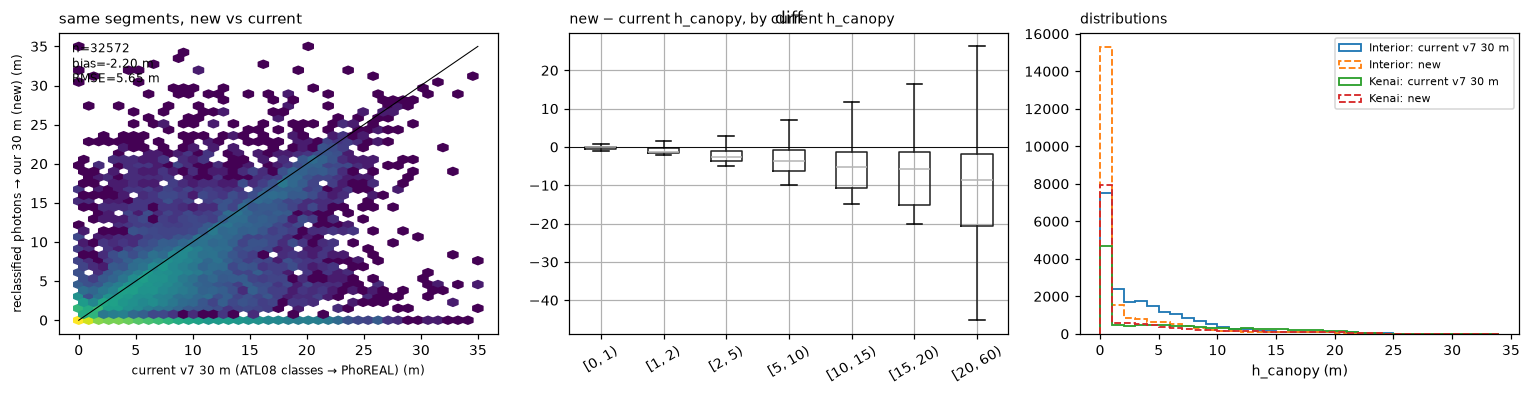

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
val.plot_scatter(axes[0], segs.h_canopy, segs.h_canopy_phoreal, "same segments, new vs current", lim=35)
axes[0].set_xlabel(val.LABEL_CURRENT + " (m)", fontsize=8); axes[0].set_ylabel(val.LABEL_NEW + " (m)", fontsize=8)
d = segs.h_canopy - segs.h_canopy_phoreal
b = pd.cut(segs.h_canopy_phoreal, [0, 1, 2, 5, 10, 15, 20, 60], right=False)
segs.assign(diff=d, bin=b).boxplot(column="diff", by="bin", ax=axes[1], showfliers=False, rot=30)
axes[1].axhline(0, c="k", lw=0.6); axes[1].set_title("new − current h_canopy, by current h_canopy", loc="left", fontsize=9); axes[1].set_xlabel(""); fig.suptitle("")
for reg, g in segs.groupby("region"):
    axes[2].hist(g.h_canopy_phoreal.dropna(), bins=np.arange(0, 35, 1), histtype="step", lw=1.2, label=f"{reg}: current v7 30 m")
    axes[2].hist(g.h_canopy.dropna(), bins=np.arange(0, 35, 1), histtype="step", lw=1.2, ls="--", label=f"{reg}: new")
axes[2].legend(fontsize=7); axes[2].set_xlabel("h_canopy (m)"); axes[2].set_title("distributions", loc="left", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "04_new_vs_current.png", dpi=150)
pd.DataFrame({"segments": segs.groupby("region").size(), "short_veg_flag": segs.groupby("region").short_veg_flag.mean().round(3),
              "matched_to_phoreal": segs.groupby("region").h_canopy_phoreal.apply(lambda v: v.notna().mean()).round(3)})

## Results
Summarise after review: binning check (bias, RMSE between our ATL08-class segments and PhoREAL), and where the reclassified
heights depart from the current files (by height bin).